# Coco Renfroe, Data in EMAT
## A Picture's Determination of Engagement on Bluesky Posts
## 10/19/2026
### Hypothesis: Posts with a picture attached have a higher mean of combined replies, reposts, and likes than text-only posts

**Theoretical Application: Posts with a photo embedded are more likely to catch a viewer's eye than text only posts, which will cause the user to interact more with these posts**

**Statistical Application: I will use the API endpoints for "get profiles" and "get author feed". "Get author feed" will allow me to get an account's replies, likes, and reposts, which will be the response objects I focus on, and "get profiles" will allow me to search for multiple accounts. I will use a small sample size of 5 public accounts to avoid timing out or other issues with python/APIs. The "embed" information in the "get author feed" API endpoint will be used to determine if the post is text only or not.**

(CITATION: I used Claude to find out what metric will tell me if a post is text only or not)



This data may be unreliable because it is a small sample size, so the statistics will not show a large overview of BlueSky users, and the large public accounts that I choose may have skewed engagement compared to smaller, personal accounts. The "embed" metric may not be an accurate representation of all posts. Engagement from posts with embedded photos may have higher engagement because of a caption or a reply, which is not something the data I'm retrieving can measure. Additionally, engagement may also be viewed through impressions, or physically viewing a post, which is not a parameter which will be returned. This may skew the results.





In [34]:
import requests
import pandas as pd

BASE = "https://public.api.bsky.app/xrpc/"
accounts = ["bsky.app","nytimes.com", "atproto.com", "theonion.com", "npr.org"]
profiles = []


for account in accounts:
    response = requests.get(
        BASE + "app.bsky.actor.getProfile",
        params= {"actor": account}, timeout=15
    )
    print(account, response.status_code)

bsky.app 200
nytimes.com 200
atproto.com 200
theonion.com 200
npr.org 200


This creates the base URL as we discussed in class that I can add to instead of retyping a large URL. The accounts chosen are large public accounts. I used the code we walked through in class as an example for me to pull the getProfile information. 

I changed nasa.gov to theonion.com because NASA was getting a 400 error

In [35]:
data = response.json()
print(data.keys())

dict_keys(['did', 'handle', 'displayName', 'avatar', 'associated', 'labels', 'createdAt', 'verification', 'description', 'indexedAt', 'followersCount', 'followsCount', 'postsCount'])


In [36]:
profiles.append({
    "did": data["did"],
    "handle": data["handle"],
    "total_posts": data.get("postsCount", 0)
})
profiles_df = pd.DataFrame(profiles)
display(profiles_df)

,did,handle,total_posts
0,did:plc:ln72v57ivz2g46uqf4xxqiuh,npr.org,19293


In [37]:
  response = requests.get(
            BASE + "app.bsky.feed.getAuthorFeed",
            params=params,
            timeout=30
        )

In [38]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

BASE = "https://public.api.bsky.app/xrpc/"

accounts = [
    "bsky.app",
    "nytimes.com",
    "atproto.com",
    "theonion.com",
    "npr.org"
]

profiles = []

for account in accounts:
    response = requests.get(
        BASE + "app.bsky.actor.getProfile",
        params={"actor": account},
        timeout=15
    )

    print(account, response.status_code)

    if response.status_code == 200:
        data = response.json()

        profiles.append({
            "did": data["did"],
            "handle": data["handle"],
            "followers_count": data.get("followersCount", 0),
            "total_posts": data.get("postsCount", 0)
        })

profiles_df = pd.DataFrame(profiles)

display(profiles_df)

bsky.app 200
nytimes.com 200
atproto.com 200
theonion.com 200
npr.org 200


,did,handle,followers_count,total_posts
0,did:plc:z72i7hdynmk6r22z27h6tvur,bsky.app,35323513,886
1,did:plc:eclio37ymobqex2ncko63h4r,nytimes.com,1352725,44537
2,did:plc:ewvi7nxzyoun6zhxrhs64oiz,atproto.com,121535,272
3,did:plc:a4pqq234yw7fqbddawjo7y35,theonion.com,1359051,8834
4,did:plc:ln72v57ivz2g46uqf4xxqiuh,npr.org,1013063,19293


I kept getting errors in my code no matter how I tried to fix it, so I fixed my syntax with Claude. I have used Claude ONLY for troublshooting my incorrect syntax in this assignment and helping with what syntax will get me the information to test my hypothesis.

In [39]:
posts = []

for handle in profiles_df["handle"]:

    params = {
        "actor": handle,
        "limit": 100
    }

    response = requests.get(
        BASE + "app.bsky.feed.getAuthorFeed",
        params=params,
        timeout=30
    )

    print(handle, response.status_code)

    if response.status_code != 200:
        continue

    data = response.json()

    for item in data.get("feed", []):


        if item.get("reason") is not None:
            continue

        post = item.get("post", {})
        record = post.get("record", {})
        embed = post.get("embed") or {}

   
        embed_type = embed.get("$type", "")

        media = embed.get("media", {})
        media_type = media.get("$type", "")

        has_image = (
            "embed.images" in embed_type
            or "embed.images" in media_type
        )

        posts.append({
            "did": post.get("author", {}).get("did"),
            "handle": handle,
            "post_uri": post.get("uri"),
            "created_at": record.get("createdAt"),
            "likes": post.get("likeCount", 0),
            "reposts": post.get("repostCount", 0),
            "replies": post.get("replyCount", 0),
            "has_image": has_image
        })

posts_df = pd.DataFrame(posts)

display(posts_df.head())

print("Total posts collected:", len(posts_df))

bsky.app 200
nytimes.com 200
atproto.com 200
theonion.com 200
npr.org 200


,did,handle,post_uri,created_at,likes,reposts,replies,has_image
0,did:plc:z72i7hdynmk6r22z27h6tvur,bsky.app,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,2026-10-20T17:14:02.246Z,16,3,1,False
1,did:plc:z72i7hdynmk6r22z27h6tvur,bsky.app,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,2026-10-20T17:09:17.167Z,53,3,2,False
2,did:plc:z72i7hdynmk6r22z27h6tvur,bsky.app,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,2026-10-20T16:01:12.410Z,431,85,25,False
3,did:plc:z72i7hdynmk6r22z27h6tvur,bsky.app,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,2026-10-19T20:53:01.192Z,1840,214,95,False
4,did:plc:z72i7hdynmk6r22z27h6tvur,bsky.app,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,2026-10-19T20:37:08.426Z,185,5,3,False


Total posts collected: 453


I will now merge the two data frames as shown by Dr. Baumgartner

In [40]:
final_df = pd.merge(
    posts_df,
    profiles_df,
    on=["did", "handle"],
    how="left"
)

final_df["total_engagement"] = (
    final_df["likes"]
    + final_df["reposts"]
    + final_df["replies"]
)

display(final_df.head(10))

,did,handle,post_uri,created_at,likes,reposts,replies,has_image,followers_count,total_posts,total_engagement
0,did:plc:z72i7hdynmk6r22z27h6tvur,bsky.app,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,2026-10-20T17:14:02.246Z,16,3,1,False,35323513,886,20
1,did:plc:z72i7hdynmk6r22z27h6tvur,bsky.app,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,2026-10-20T17:09:17.167Z,53,3,2,False,35323513,886,58
2,did:plc:z72i7hdynmk6r22z27h6tvur,bsky.app,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,2026-10-20T16:01:12.410Z,431,85,25,False,35323513,886,541
3,did:plc:z72i7hdynmk6r22z27h6tvur,bsky.app,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,2026-10-19T20:53:01.192Z,1840,214,95,False,35323513,886,2149
4,did:plc:z72i7hdynmk6r22z27h6tvur,bsky.app,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,2026-10-19T20:37:08.426Z,185,5,3,False,35323513,886,193
5,did:plc:z72i7hdynmk6r22z27h6tvur,bsky.app,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,2026-10-19T18:12:43.693Z,54,4,1,False,35323513,886,59
6,did:plc:z72i7hdynmk6r22z27h6tvur,bsky.app,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,2026-10-17T21:55:13.889Z,9092,1764,660,False,35323513,886,11516
7,did:plc:z72i7hdynmk6r22z27h6tvur,bsky.app,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,2026-10-16T20:09:31.738Z,1046,116,114,False,35323513,886,1276
8,did:plc:z72i7hdynmk6r22z27h6tvur,bsky.app,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,2026-10-16T16:40:55.242Z,161,2,6,False,35323513,886,169
9,did:plc:z72i7hdynmk6r22z27h6tvur,bsky.app,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,2026-10-16T16:23:26.498Z,1433,205,179,False,35323513,886,1817


,post_type,number_of_posts,average_engagement,median_engagement
0,Posts with images,85,1467.670588,864.0
1,Text-only posts,368,340.173913,119.0


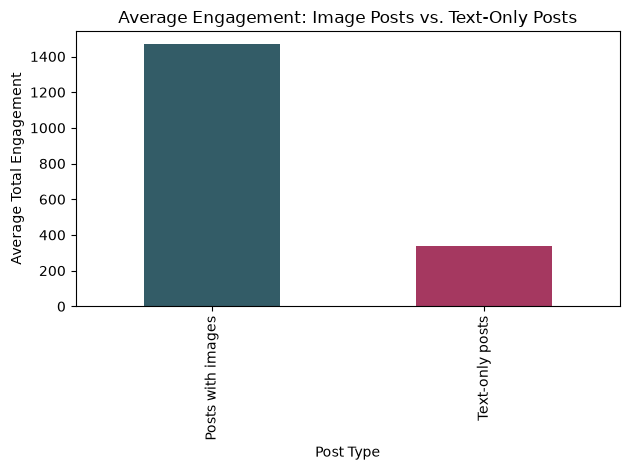

In [48]:


posts_df["total_engagement"] = (
    posts_df["likes"] +
    posts_df["reposts"] +
    posts_df["replies"]
)

posts_df["post_type"] = posts_df["has_image"].map({
    True: "Posts with images",
    False: "Text-only posts"
})

engagement_summary = posts_df.groupby("post_type").agg(
    number_of_posts=("post_uri", "count"),
    average_engagement=("total_engagement", "mean"),
    median_engagement=("total_engagement", "median")
).reset_index()

display(engagement_summary)

engagement_by_type = posts_df.groupby("post_type")[
    "total_engagement"
].mean()

engagement_by_type.plot(
    kind="bar",
    title="Average Engagement: Image Posts vs. Text-Only Posts",
    xlabel="Post Type",
    ylabel="Average Total Engagement",
   color=["#335c67", "#a53860"],
)

plt.tight_layout()
plt.show()

From the preliminary data I gathered, it appears that posts with images *do* have a higher mean likes, reposts, and replies than text only posts. This is not "proving" my hypothesis, as a hypothesis needs to be tested and retested, and the sample size is small and specific, but it's pointing me in the right direction for further data gathering. With this small sample size, my original hypothesis shows promise.


The engagement that I was able to collect was limited to likes, reposts, and replies. This may not be showing incredibly accurate data, because engagement among many platforms includes impressions, and many other engagement metrics. This means my data is not measuring ALL engagement. The API was limited in its responses, so I was not able to gather a wider range of engagement metrics, and some carry more weight than others.

There is also the issue that my data reflects ALL engagement for an actor and is not dependent on engagement from followers only. In the future, I may wrangle the data to be listed for followers of each account only to get more accurate data, though this might actually change the hypothesis. It would not technically be testing the hypothesis that I started out with. I also would love to expand this hypothesis to other social platforms, if they had open APIs that I could use to test on. I would also test more accounts to make my stats reflect the larger user platform on Bluesky, though that may require higher computing power than my computer can handle.